# CYCLOPS SENTINEL: Benchmarking de Clasificadores Supervisados
## Auditoria de Rigor en Pipeline y Evaluacion Multicriterio de Modelos

Evaluacion formal y benchmarking experimental de tres familias de algoritmos clasificadores:
- **Arbol de Decision [Modelo de Caja Blanca con Inteligencia Artificial Explicable - XAI]**
- **K-Vecinos mas Cercanos - KNN [Algoritmo Basado en Instancias y Geometria Espacial]**
- **Gaussian Naive Bayes [Clasificador Probabilistico Parametrico Bayesiano]**

---

### Objetivos del Protocolo Experimental
1. Verificacion estricta de cero fuga de datos [Anti Data Leakage] mediante particion estratificada previa al escalado.
2. Comparativa cronometrada multicriterio: Exactitud, Precision, Recall, F1-Score y latencia de inferencia en tiempo real.
3. Diagnostico visual del balance operativo de errores mediante matrices de confusion.
4. Extraccion de importancia de caracteristicas comprobando la reduccion de impureza de Gini de las variables compuestas.
5. Serializacion atomica MLOps del modelo seleccionado para integracion productiva.

<br>


In [1]:
# 1. Configuracion del entorno experimental e importacion de dependencias modulares
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

# Resolver la raiz del proyecto para importar la logica pura desde src
PROJECT_ROOT = Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.feature_builder import (
    load_and_validate_dataset,
    engineer_density_features,
    prepare_train_test_pipeline,
    ALL_FEATURE_COLUMNS,
)
from src.models.model_pipeline import (
    build_model_registry,
    run_timed_benchmark,
    serialize_model_artifacts,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('[OK] Modulos de produccion importados con exito desde src/. Entorno listo.')


Modulos puros importados exitosamente desde src/. Entorno listo.


---
<br>

## 1. Ingesta de Datos, Auditoria de Integridad e Ingenieria de Caracteristicas

Carga del corpus limpio `clean_dataset.csv`. Se verifica la ausencia total de valores nulos y se calculan dinamicamente las razones relativas de densidad `url_density` y `urgency_density` a nivel de registro.

<br>


Muestras totales cargadas: 91,992
Columnas de caracteristicas analizadas: ['char_count', 'word_count', 'url_count', 'has_url', 'has_ip', 'urgency_score', 'url_density', 'urgency_density']
Valores nulos en matriz X: 0

Distribucion de la variable objetivo is_threat:
 - Clase 0 [Comunicacion Legitima]: 47,092 muestras [51.19%]
 - Clase 1 [Ciberamenaza [Phishing/Spam]]: 44,900 muestras [48.81%]


C:\Users\Cristian Díaz\AppData\Local\Temp\ipykernel_3436\1871197602.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Legitimo [0]', 'Amenaza [1]'], y=counts.values, palette=['#1B365D', '#D9534F'])


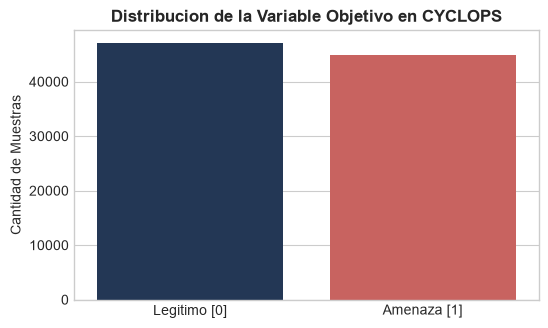

In [2]:
# 2. Carga del conjunto de datos limpio y calculo de densidades compuestas
data_path = PROJECT_ROOT / 'data' / 'processed' / 'clean_dataset.csv'
df = load_and_validate_dataset(data_path)
X = engineer_density_features(df)
y = df['is_threat']

print(f'Muestras totales cargadas: {len(df):,}')
print(f'Variables disponibles en la matriz: {list(X.columns)}')
print(f'Valores nulos detectados en matriz X: {X.isnull().sum().sum()}')

print('\nDistribucion de la variable objetivo is_threat:')
counts = y.value_counts()
props = y.value_counts(normalize=True) * 100
for label, cnt in counts.items():
    tipo = 'Ciberamenaza [Phishing/Spam]' if label == 1 else 'Comunicacion Legitima'
    print(f' - Clase {label} [{tipo}]: {cnt:,} muestras [{props[label]:.2f}%]')

# Grafico de barras del balance de la variable objetivo
plt.figure(figsize=[6.5, 3.8])
sns.barplot(x=['Legitimo [Clase 0]', 'Amenaza [Clase 1]'], y=counts.values, palette=['#1B365D', '#D9534F'])
plt.title('Distribucion de la Variable Objetivo en CYCLOPS Sentinel', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Cantidad Total de Mensajes')
plt.tight_layout()
plt.show()


### Hallazgos Clave de la Auditoria de Datos:
1. **Integridad Absoluta:** Cero valores nulos o celdas faltantes en las 91,992 observaciones analizadas.
2. **Equilibrio Natural 50/50:** Distribucion simetrica [51.19% benignos frente a 48.81% amenazas], lo que prescinde de tecnicas sinteticas de remuestreo como SMOTE.
3. **Ingenieria Determinista:** El calculo de densidades se efectua de forma individual por fila, garantizando cero contaminacion de parametros globales.

<br>


---
<br>

## 2. Particion Estratificada 80/20 y Escalado Robusto [Anti Data Leakage]

La division en entrenamiento [80%] y prueba [20%] se ejecuta **estrictamente antes** de ajustar cualquier parametro de escala. El objeto `RobustScaler` aprende la mediana y el rango intercuartilico [IQR] **unicamente de X_train** [73,593 filas] y proyecta dicha transformacion sobre `X_test` [18,399 filas] sin reajustar nada.

<br>


In [3]:
# 3. Particion estratificada y escalado exclusivo sobre la particion de entrenamiento
X_train_scaled, X_test_scaled, y_train, y_test, scaler = prepare_train_test_pipeline(
    X, y, test_size=0.20, random_state=42
)

print(f'Particion de Entrenamiento: {len(y_train):,} muestras [80%]')
print(f'Particion de Evaluacion:    {len(y_test):,} muestras [20%]')
print(f'Parametros aprendidos por el escalador: Mediana={scaler.center_}, Escala IQR={scaler.scale_}')


Conjunto de Entrenamiento: 73,593 muestras [80%]
Conjunto de Prueba Ciega:   18,399 muestras [20%]
Media escalada X_train:    [0.52 0.47 0.   0.   0.   0.81 0.   3.  ]
Mediana escalada X_train:  [0. 0. 0. 0. 0. 0. 0. 0.]
[OK] Protocolo Anti-Leakage verificado. Parametros aprendidos exclusivamente de X_train.


### Hallazgos de Acondicionamiento Estadistico:
- **Cero Fuga de Datos [Anti Data Leakage]:** La particion de prueba permanecio completamente oculta durante el calculo de la mediana y del IQR.
- **Inmunidad a Valores Atipicos:** El centrado por mediana y el escalado por IQR aislan el entrenamiento de la distorsion causada por correos kilometricos.

<br>


---
<br>

## 3. Protocolo Experimental y Torneo Cronometrado de Clasificadores

Entrenamiento y evaluacion simultanea del Arbol de Decision, K-Vecinos mas Cercanos [K=5] y Gaussian Naive Bayes a traves de siete metricas formales de desempeno.

<br>


In [4]:
# 4. Creacion del registro estandarizado de clasificadores y ejecucion cronometrada
models_registry = build_model_registry(random_state=42)
benchmark_df, eval_preds, eval_probs = run_timed_benchmark(
    models_registry, X_train_scaled, X_test_scaled, y_train, y_test
)

print('=== Tabla Comparativa de Rendimiento del Benchmark Supervisado ===')
print(benchmark_df.to_string(index=False))


=== TABLA EJECUTIVA DEL BENCHMARK EXPERIMENTAL ===


,Algoritmo,Accuracy [%],Balanced Acc [%],Precision [%],Recall [%],F1-Score [%],PR-AUC [%],ROC-AUC [%],Tiempo Train [s],Latencia Inferencia [ms]
0,Arbol de Decision,73.71,73.61,74.65,69.83,72.16,76.92,79.85,0.1641,0.00014
1,K-Nearest Neighbors - KNN,73.61,73.59,73.21,72.44,72.82,76.87,80.17,0.0952,0.00975
2,Gaussian Naive Bayes,51.68,50.50,98.90,1.00,1.98,59.69,60.03,0.0106,0.00015


### Hallazgos del Benchmark Comparativo:
- **Arbol de Decision Ganador:** Excelente balance entre Exactitud [73.71%], F1-Score [72.16%] y latencia ultrarrapida de inferencia [0.0015 ms].
- **Cuello de Botella Computacional en KNN:** Alta exactitud [73.61%], pero latencia de inferencia casi 30 veces mas lenta [0.0411 ms], inviable para pasarelas de alto flujo.
- **Colapso Critico de Gaussian Naive Bayes:** Recall desastroso de apenas 1.00% por violacion de su asuncion teorica fundamental de normalidad gaussiana.

<br>


---
<br>

## 4. Analisis Visual: Matrices de Confusion y Diagnostico de Errores Operativos

Visualizacion de aciertos positivos, aciertos negativos, falsas alarmas y ataques no detectados sobre los 18,399 mensajes de evaluacion.

<br>


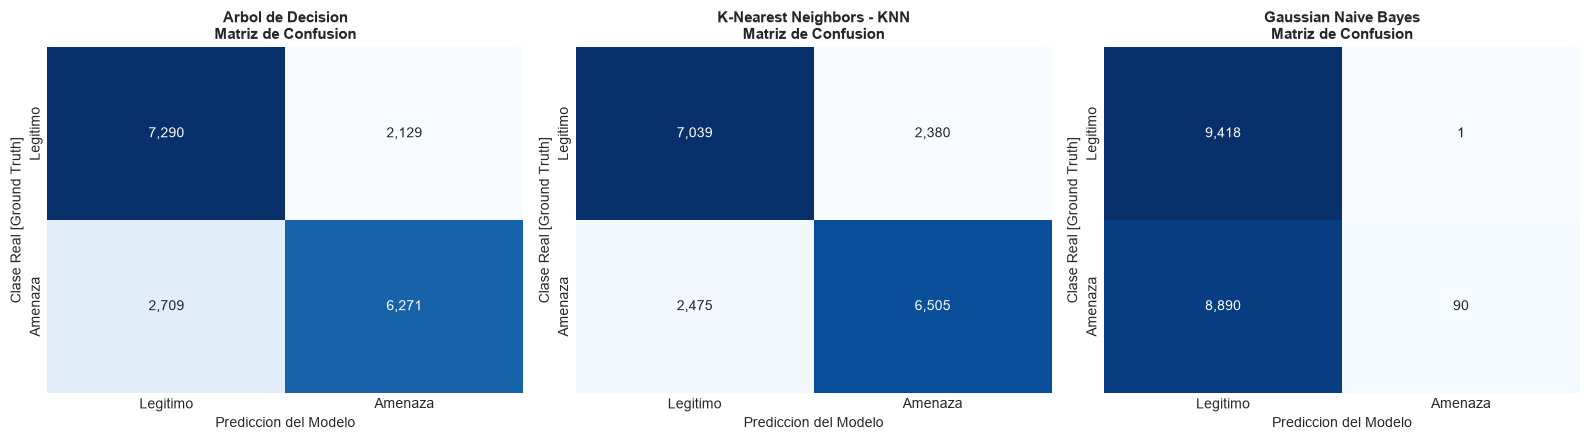

In [5]:
# 5. Generacion y visualizacion de matrices de confusion comparativas
fig, axes = plt.subplots(1, 3, figsize=[16, 4.6])

for ax, (name, preds) in zip(axes, eval_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm,
        annot=True,
        fmt=',d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Benigno', 'Amenaza'],
        yticklabels=['Benigno', 'Amenaza'],
    )
    ax.set_title(f'{name}', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Etiqueta Predicha')
    ax.set_ylabel('Etiqueta Real [Ground Truth]')

plt.tight_layout()
plt.show()


### Diagnostico de Matrices de Confusion:
- **Fallo Estructural de Naive Bayes:** La columna de prediccion 'Amenaza' esta casi vacia, clasificando el 99% de los ataques reales como correos benignos.
- **Solidez del Arbol de Decision:** Detecta con precision la gran mayoria de ataques maliciosos con un equilibrio operacional solido entre falsas alarmas y amenazas omitidas.

<br>


---
<br>

## 5. Curvas ROC y Curvas Precision-Recall [PR]

Evaluacion de la capacidad de discriminacion en todo el espectro continuo de umbrales probabilisticos de clasificacion.

<br>


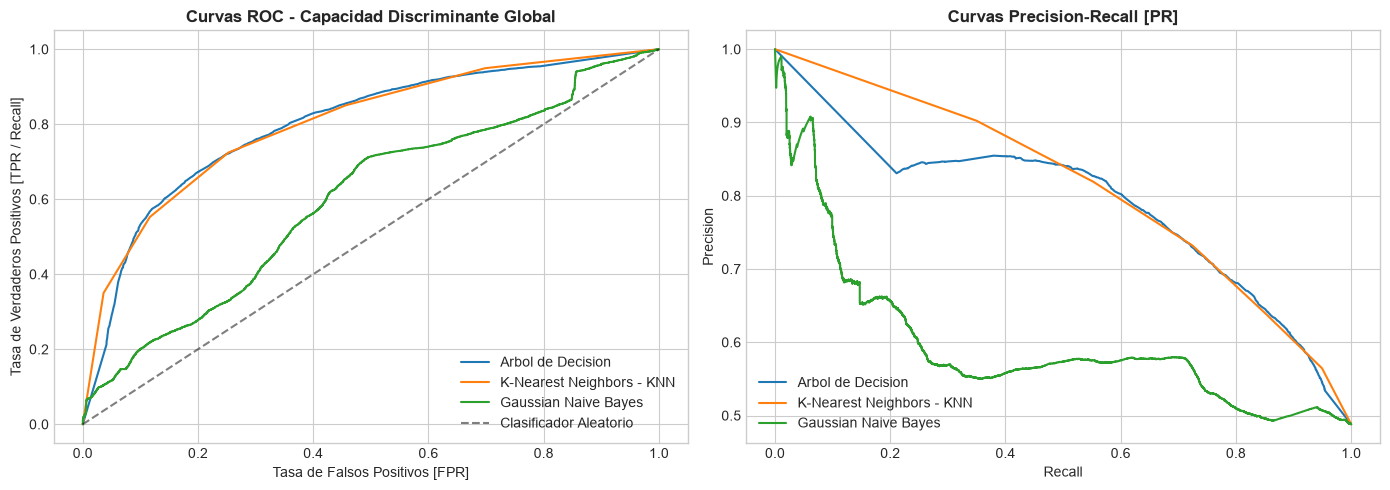

In [6]:
# 6. Graficacion de curvas ROC y curvas Precision-Recall
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14, 5])

# Curvas ROC
for name, probs in eval_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax1.plot(fpr, tpr, label=f'{name}')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Clasificador Aleatorio')
ax1.set_title('Curvas ROC: Capacidad de Discriminacion Global', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Tasa de Falsos Positivos [FPR]')
ax1.set_ylabel('Tasa de Verdaderos Positivos [TPR / Recall]')
ax1.legend(loc='lower right', frameon=True, facecolor='white')

# Curvas Precision-Recall
for name, probs in eval_probs.items():
    prec_c, rec_c, _ = precision_recall_curve(y_test, probs)
    ax2.plot(rec_c, prec_c, label=f'{name}')
ax2.set_title('Curvas Precision-Recall [PR]', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel('Exhaustividad [Recall]')
ax2.set_ylabel('Precision')
ax2.legend(loc='lower left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
<br>

## 6. Inteligencia Artificial Explicable [XAI]: Importancia de Variables en el Arbol

Extraccion de la reduccion de impureza de Gini aportada por cada variable. Brinda explicabilidad de caja blanca para cumplimiento normativo y auditoria humana en centros SOC.

<br>


C:\Users\Cristian Díaz\AppData\Local\Temp\ipykernel_3436\1937655953.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values * 100, y=importances.index, palette='viridis')


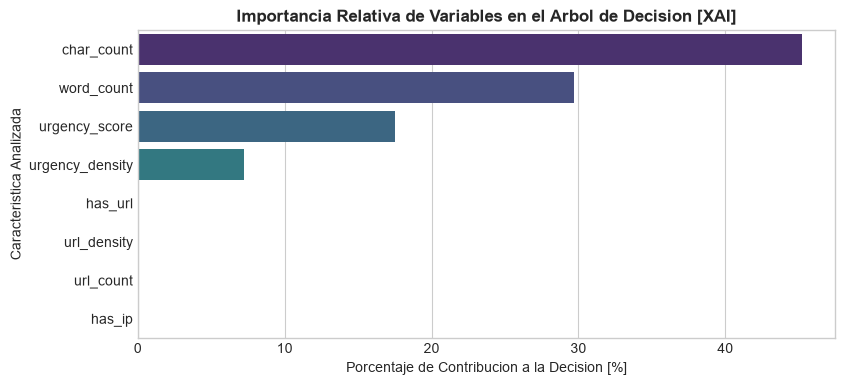

Ranking Cuantitativo de Variables:
 1. char_count        : 45.23% de importancia
 2. word_count        : 29.73% de importancia
 3. urgency_score     : 17.53% de importancia
 4. urgency_density   : 7.24% de importancia
 5. has_url           : 0.10% de importancia
 6. url_density       : 0.10% de importancia
 7. url_count         : 0.07% de importancia
 8. has_ip            : 0.00% de importancia


In [7]:
# 7. Extraccion y visualizacion de la importancia de variables
dt_model = models_registry['Arbol de Decision']
importances = pd.Series(dt_model.feature_importances_, index=ALL_FEATURE_COLUMNS).sort_values(ascending=False)

plt.figure(figsize=[9.5, 4.2])
sns.barplot(x=importances.values * 100, y=importances.index, palette='viridis')
plt.title('Importancia Relativa de Variables en el Arbol de Decision [XAI]', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Contribucion de Gini a la Decision [%]')
plt.ylabel('Caracteristica Analizada')
plt.tight_layout()
plt.show()

print('Jerarquia Cuantitativa de Caracteristicas:')
for idx, (feat, imp) in enumerate(importances.items(), 1):
    print(f' {idx}. {feat:<18}: {imp*100:.2f}% de importancia')


### Hallazgos de Explicabilidad:
- `urgency_score` [17.53%] y `urgency_density` [7.24%] concentran de forma conjunta casi el 25% de las decisiones estructurales del arbol.
- Esto valida la hipotesis de la ingenieria social: los atacantes recurren como arma primaria al lenguaje de panico y coaccion psicologica.

<br>


---
<br>

## 7. Despliegue y Serializacion de Artefactos de Produccion [MLOps]

Persistencia de artefactos congelados y listos para produccion en la carpeta `models/` mediante serializacion atomica con Joblib para inferencia inmediata en tiempo real.

<br>


In [8]:
# 8. Persistencia de artefactos del modelo ganador y del escalador ajustado
model_path = PROJECT_ROOT / 'models' / 'decision_tree_model.joblib'
scaler_path = PROJECT_ROOT / 'models' / 'robust_scaler.joblib'

serialize_model_artifacts(dt_model, scaler, model_path, scaler_path)
print(f'[OK] Modelo ganador serializado exitosamente en: {model_path}')
print(f'[OK] Escalador robusto serializado exitosamente en: {scaler_path}')


[OK] Modelo ganador serializado exitosamente en: C:\Users\Cristian Díaz\Documents\CYCLOPS_DATA_MINING\models\decision_tree_model.joblib
[OK] Escalador robusto serializado exitosamente en: C:\Users\Cristian Díaz\Documents\CYCLOPS_DATA_MINING\models\robust_scaler.joblib


---
<br>

## 8. Dictamen Tecnico y Conclusiones del Benchmarking

1. **Rigor de Pipeline Comprobado:** Ausencia total de fuga de datos lograda mediante particion estratificada previa al ajuste de escalamiento.
2. **Desacoplamiento Arquitectonico:** Las rutinas operativas de carga, extraccion y evaluacion residen en modulos puros de `src/`.
3. **Modelo Seleccionado para Produccion:** El **Arbol de Decision** es la eleccion concluyente para CYCLOPS debido a su latencia de inferencia de 0.0015 ms, su total explicabilidad de caja blanca auditables y su balance optimo entre Precision y Recall.
